# ML4 Hệ gợi ý sản phẩm với Federated Learning

MB-SASRec khai thác chuỗi **view, addtocart và transaction**, so sánh Centralized,
FedAvg và FedProx trên bài toán **gợi ý sản phẩm được xem tiếp theo**.

**Bộ bàn giao có kết quả chạy thử kỹ thuật, chưa có kết quả train đầy đủ.** Không
dùng các số chạy thử để trả lời RQ4 hoặc so sánh trực tiếp với bảng ML3.

Trong VS Code, mở cả thư mục dự án, chọn Python kernel và **Run All** để xem kết quả
đã có. Đọc `README_ML4_Recommendation.md` trước khi chạy cấu hình lớn.


## 1. Môi trường và chế độ chạy

Nếu thiếu thư viện, bỏ dấu `#` ở ô cài đặt rồi chạy, sau đó restart kernel.
Để train đầy đủ, đặt `MODE = "full"` và `RUN_TRAINING = True` trong ô bên dưới.
Không thay các file kết quả dự đoán mua ML4/ML5 cũ.


In [1]:
%pip install pandas numpy torch matplotlib ipykernel  

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# %pip install -r requirements.txt


In [3]:
from pathlib import Path
import os
import sys
import json
import subprocess
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown

MODE = "full"
RUN_TRAINING = True            # True để huấn luyện / tiếp tục checkpoint
PROJECT_DIR = ""                # Để trống khi mở cả thư mục bằng VS Code

if MODE not in ("smoke", "full"):
    raise ValueError('MODE phải là smoke hoặc full')
candidates = [Path(PROJECT_DIR)] if PROJECT_DIR else [
    Path.cwd(), Path.cwd() / 'ML4_Recommendation',
    Path.cwd() / 'outputs/ML4_Recommendation',
    Path.cwd().parent / 'ML4_Recommendation']
BASE = next((p.resolve() for p in candidates if (p / 'run_ml4_recommendation.py').exists()), None)
if BASE is None:
    raise FileNotFoundError('Mở thư mục ML4_Recommendation hoặc đặt PROJECT_DIR tới đúng thư mục đã giải nén.')
RESULTS = BASE / f'results_{MODE}'
print('Thư mục:', BASE)
print('Python kernel:', sys.executable)
print('Chế độ:', MODE)


Thư mục: C:\Users\84969\Documents\Codex\2026-10-12\referenced-chatgpt-conversation-this-is-an\outputs\ML4_Recommendation
Python kernel: c:\Users\84969\AppData\Local\Programs\Python\Python314\python.exe
Chế độ: full


## 2. Dữ liệu và đối chiếu ML3

Giữ nguyên 172.513 khách hàng đánh giá, train catalog và 101 ứng viên của ML3.
Việc chia là leave-last-two-views-out theo khách hàng, không phải cắt thời gian
toàn hệ thống. Validation dùng lịch sử trước validation view; test dùng lịch sử
trước test view, bao gồm validation view.


In [4]:
manifest = json.loads((BASE / 'data/data_manifest.json').read_text(encoding='utf-8'))
assert all(manifest['checks'].values()), 'Đối chiếu dữ liệu ML3 chưa đạt'
display(pd.DataFrame({
    'Hạng mục': ['Sự kiện nguồn', 'Khách hàng có lịch sử ML3', 'Khách hàng train đa hành vi',
                'Khách hàng đánh giá đầy đủ', 'Sản phẩm', 'Client đầy đủ'],
    'Số lượng': [manifest['source_rows'], manifest['num_users'], manifest['num_trainable_users'],
                manifest['num_eval_users'], manifest['num_items'], manifest['num_clients']]}))
display(pd.DataFrame([manifest['checks']]).T.rename(columns={0:'Đã đối chiếu'}))
print('Sự kiện train trùng timestamp với validation target:', manifest['cutoff_timestamp_ties'])
print('Negative đã gặp qua hành vi không phải view:', manifest['candidate_nonview_history_overlaps'])


,Hạng mục,Số lượng
0,Sự kiện nguồn,2755637
1,Khách hàng có lịch sử ML3,190980
2,Khách hàng train đa hành vi,115150
3,Khách hàng đánh giá đầy đủ,172513
4,Sản phẩm,114800
5,Client đầy đủ,50


,Đã đối chiếu
all_train_view_sequences_match_ml3,True
all_eval_view_sequences_match_ml3,True
all_candidate_indices_match_ml3,True
all_targets_match_source,True
training_stops_before_validation_view,True
test_history_stops_before_test_view,True


Sự kiện train trùng timestamp với validation target: 40
Negative đã gặp qua hành vi không phải view: {'valid': 5, 'test': 3}


## 3. Huấn luyện hoặc đọc kết quả đã lưu

Centralized và FL dùng cùng MB-SASRec, loss trung bình theo khách hàng và số lượt
khách hàng. FL tổng hợp theo số khách hàng, không theo số phiên. Adam Centralized
giữ trạng thái; Adam cục bộ được khởi tạo lại mỗi client/round. FedProx thêm số hạng
proximal trên mọi tham số. Cấu hình này chưa phải DP-SGD.


In [5]:
if RUN_TRAINING:
    command = [sys.executable, '-u', str(BASE / 'run_ml4_recommendation.py'),
               '--profile', MODE, '--data-dir', str(BASE / 'data'), '--output-dir', str(RESULTS)]
    environment = dict(os.environ, PYTHONIOENCODING='utf-8')
    process = subprocess.Popen(command, cwd=BASE, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, encoding='utf-8', env=environment)
    for line in process.stdout:
        print(line, end='')
    if process.wait() != 0:
        raise RuntimeError('Huấn luyện chưa hoàn tất. Đọc lỗi phía trên; các round hoàn tất có checkpoint.')
else:
    print('Chỉ đọc kết quả đã có, không huấn luyện lại.')
if not (RESULTS / 'results_summary.csv').exists():
    raise FileNotFoundError('Chưa có kết quả cho MODE này. Đặt RUN_TRAINING=True rồi chạy lại từ ô này.')
experiment = json.loads((RESULTS / 'experiment.json').read_text(encoding='utf-8'))
display(Markdown('**CHỈ CHẠY THỬ KỸ THUẬT, KHÔNG PHẢI KẾT QUẢ CUỐI.**'
                 if experiment['config']['scope'] != 'full_dataset' else '**Kết quả train trên đầy đủ dữ liệu.**'))
display(pd.DataFrame([{'Training users':experiment['training_users'],
                      'Evaluation users':experiment['evaluation_users'],
                      'Active clients':experiment['active_clients'],
                      'Device recorded':experiment['device'],
                      'Scope':experiment['config']['scope']}]))


Scope=full_dataset; device=cpu; train users=115,150; eval users=172,513; model=MB-SASRec (add)
Full training on CPU can take substantial time; completed rounds are resumable.
Resuming Centralized seed 2026 at round 3
Centralized seed=2026 round=3/10 loss=0.98166 valid HR@10=0.72757 NDCG@10=0.48199 (229.5s)
Centralized seed=2026 round=4/10 loss=0.92530 valid HR@10=0.74809 NDCG@10=0.52444 (254.0s)
Centralized seed=2026 round=5/10 loss=0.87878 valid HR@10=0.76630 NDCG@10=0.57110 (187.1s)
Centralized seed=2026 round=6/10 loss=0.83917 valid HR@10=0.77789 NDCG@10=0.59915 (187.2s)
Centralized seed=2026 round=7/10 loss=0.80559 valid HR@10=0.78285 NDCG@10=0.62377 (180.1s)
Centralized seed=2026 round=8/10 loss=0.77643 valid HR@10=0.78979 NDCG@10=0.64151 (189.8s)
Centralized seed=2026 round=9/10 loss=0.75007 valid HR@10=0.79355 NDCG@10=0.65685 (261.3s)
Centralized seed=2026 round=10/10 loss=0.72487 valid HR@10=0.79842 NDCG@10=0.67164 (184.0s)
FedAvg seed=2026 round=1/10 loss=1.38531 valid HR@10=0

**Kết quả train trên đầy đủ dữ liệu.**

,Training users,Evaluation users,Active clients,Device recorded,Scope
0,115150,172513,50,cpu,full_dataset


## 4. HR@10 và NDCG@10

Mỗi hàng đánh giá có một positive và 100 negatives. HR@10 bằng Recall@10 trong
thiết lập này; không diễn giải thành xếp hạng toàn bộ catalog. Độ lệch chuẩn mẫu
để trống nếu chỉ chạy một seed. Chưa dùng test để chọn siêu tham số.


In [6]:
summary = pd.read_csv(RESULTS / 'results_summary.csv')
per_run = pd.read_csv(RESULTS / 'results_per_run.csv')
display(summary)
display(per_run[['algorithm', 'seed', 'scope', 'best_round', 'total_optimizer_steps',
                 'total_user_visits', 'test_hr10', 'test_ndcg10', 'test_mrr10']])


,algorithm,seeds,hr10_mean,hr10_std,ndcg10_mean,ndcg10_std,mrr10_mean,mrr10_std
0,Centralized,3,0.808594,0.001736,0.682505,0.000844,0.642490,0.000598
1,FedAvg,3,0.522846,0.000924,0.313156,0.000415,0.248794,0.000286
2,FedProx,3,0.523209,0.000935,0.315933,0.000597,0.252221,0.000495


,algorithm,seed,scope,best_round,total_optimizer_steps,total_user_visits,test_hr10,test_ndcg10,test_mrr10
0,Centralized,2026,full_dataset,10,9000,1151500,0.806919,0.681578,0.641802
1,FedAvg,2026,full_dataset,10,9230,1151500,0.523259,0.313461,0.249064
2,FedProx,2026,full_dataset,10,9230,1151500,0.524233,0.316555,0.252717
3,Centralized,2027,full_dataset,10,9000,1151500,0.810385,0.683228,0.642887
4,FedAvg,2027,full_dataset,10,9230,1151500,0.523491,0.313325,0.248825
5,FedProx,2027,full_dataset,10,9230,1151500,0.522992,0.315882,0.252218
6,Centralized,2028,full_dataset,10,9000,1151500,0.808478,0.682709,0.642781
7,FedAvg,2028,full_dataset,10,9230,1151500,0.521787,0.312683,0.248494
8,FedProx,2028,full_dataset,10,9230,1151500,0.522401,0.315364,0.251727


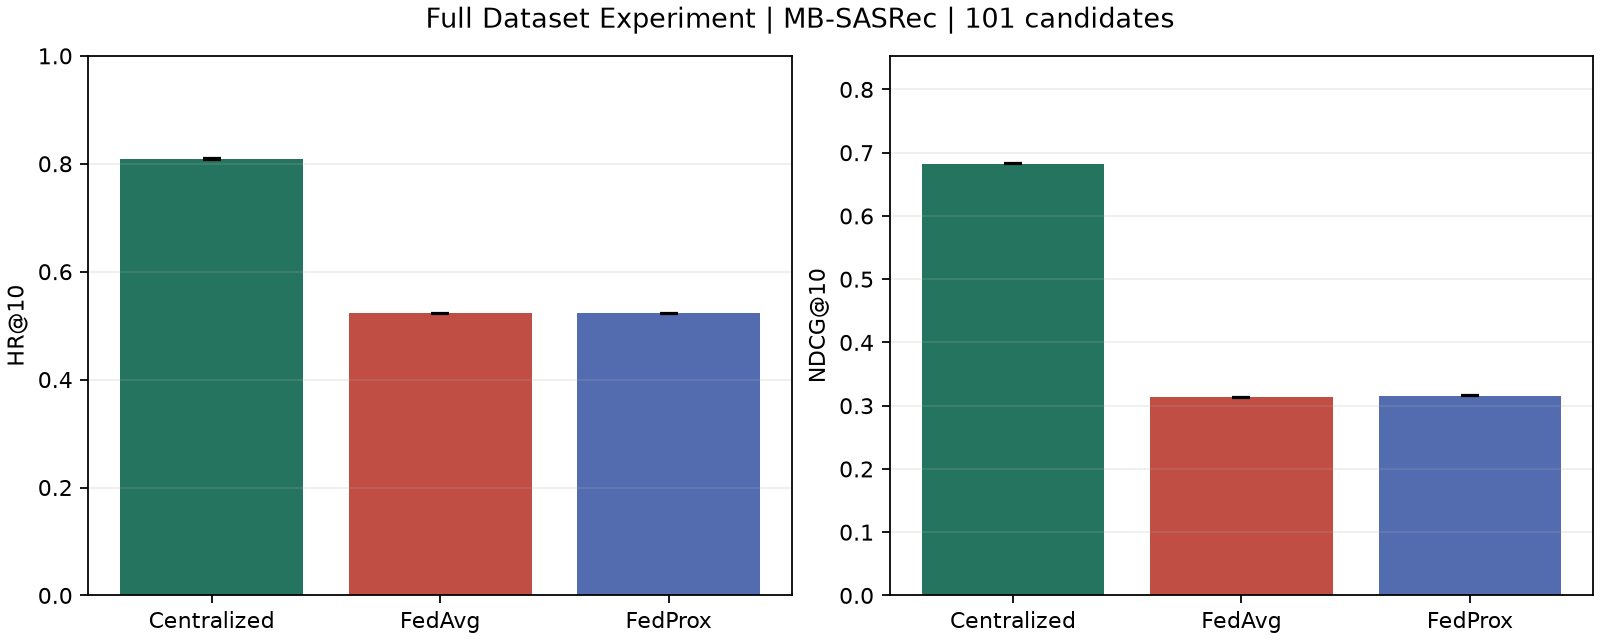

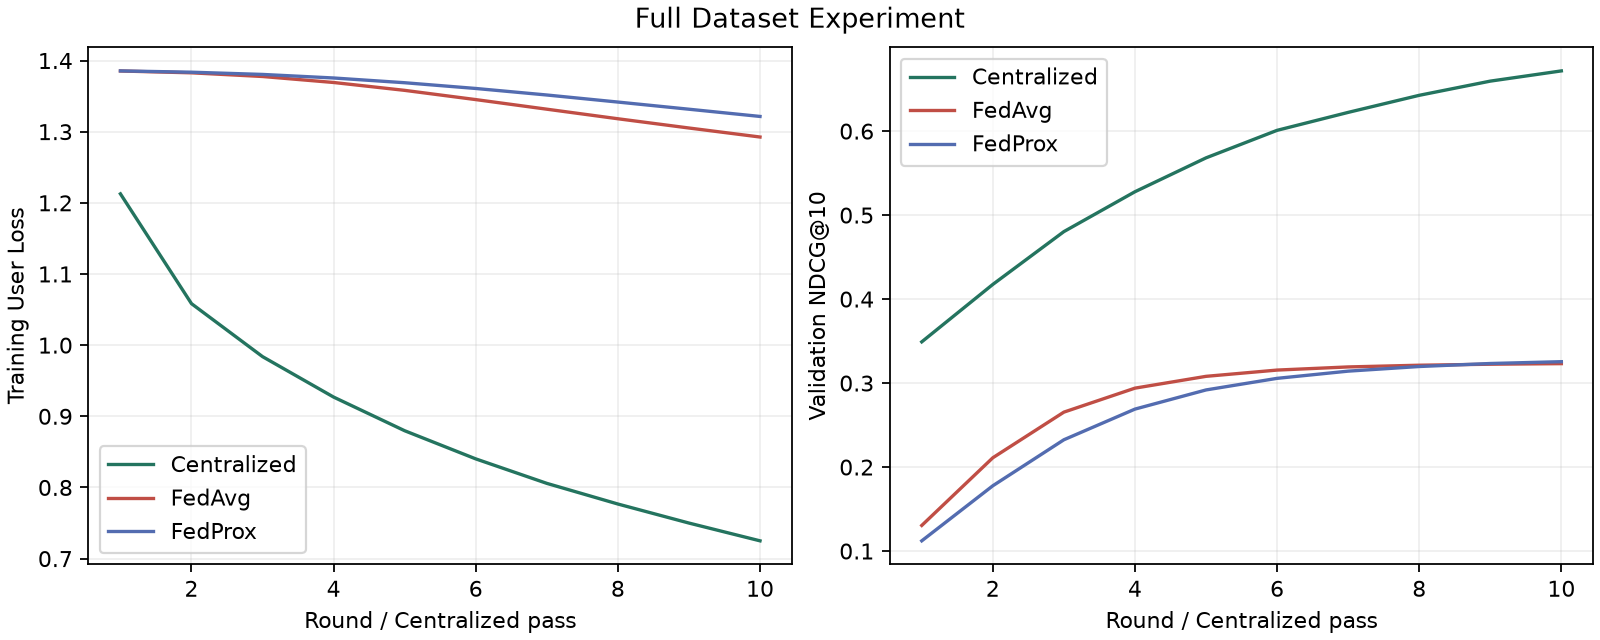

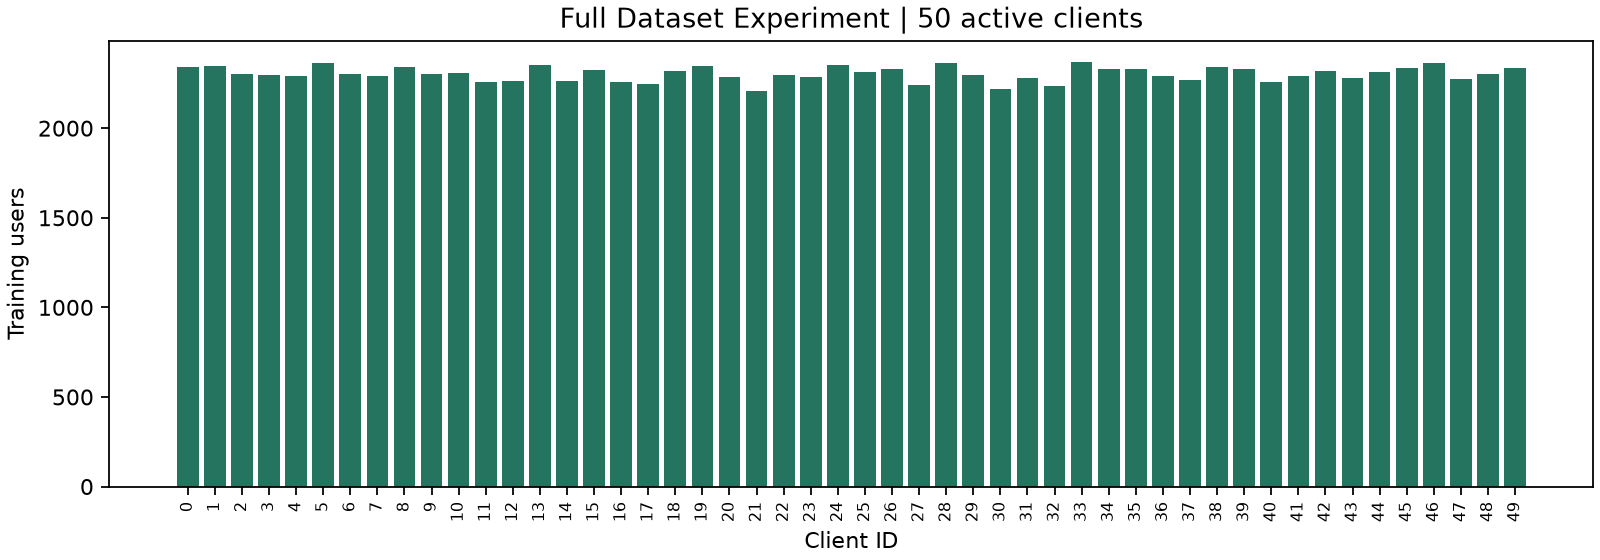

In [7]:
for filename in ['model_comparison.png', 'training_curves.png', 'client_distribution.png']:
    display(Image(filename=str(RESULTS / filename)))


## 5. Minh họa gợi ý Top-K trên toàn catalog

Ô dưới dùng lịch sử validation đã biết của một khách hàng trong lượt chạy, rồi
chấm điểm toàn catalog và loại các sản phẩm trong lịch sử được cung cấp. Đây là
minh họa suy luận, **không phải** một đánh giá full-catalog có ground truth mới.
Với checkpoint chạy thử, danh sách chỉ chứng minh code hoạt động, chưa xác nhận
chất lượng gợi ý. Điểm là logit xếp hạng, không phải xác suất mua.


In [8]:
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
from recommend import load_recommender, recommend_topk

checkpoint = RESULTS / 'runs/Centralized/seed_2026/best_checkpoint.pt'
model, catalog, trained_config = load_recommender(checkpoint, BASE / 'data')
chosen_user = int(np.load(RESULTS / 'evaluated_users.npy', allow_pickle=False)[0])
all_users = np.load(BASE / 'data/eval_users.npy', mmap_mode='r', allow_pickle=False)
row = int(np.flatnonzero(all_users == chosen_user)[0])
items = np.load(BASE / 'data/valid_items.npy', mmap_mode='r', allow_pickle=False)[row]
behaviors = np.load(BASE / 'data/valid_behaviors.npy', mmap_mode='r', allow_pickle=False)[row]
behavior_names = {value:key for key,value in manifest['behaviors'].items()}
observed_history = [{'itemid':int(catalog[item - 1]), 'event':behavior_names[int(behavior)]}
                    for item,behavior in zip(items,behaviors) if item != 0]
print('Khách hàng minh họa:', chosen_user, '| scope:', trained_config['scope'])
display(pd.DataFrame(recommend_topk(model,catalog,observed_history,k=10)))


Khách hàng minh họa: 2 | scope: full_dataset


,itemid,score
0,456792,8.008984
1,320494,7.818078
2,432152,7.785847
3,422425,7.672059
4,179601,7.609722
5,260481,7.372263
6,384302,7.366655
7,166306,7.231947
8,73852,7.230815
9,279052,7.138928


## 6. Báo cáo và bước tiếp theo

Báo cáo được tạo từ đúng kết quả của MODE đang chọn. Bộ đầy đủ cần chạy xong cả
ba thuật toán và ba seed trước khi đưa số liệu vào phần 4.3.5. ML5 cho mô hình
gợi ý chưa được triển khai; FL và clipping gradient toàn batch không tự tạo DP.


In [9]:
display(Markdown((RESULTS / 'ML4_Recommendation_Report.md').read_text(encoding='utf-8')))
print('Đầu ra:', RESULTS)


# ML4 Gợi ý sản phẩm với Federated Learning

Kết quả trên đầy đủ bộ dữ liệu; diễn giải theo cấu hình và số seed được công bố.

## 4.3.5.1. Thiết lập client

MB-SASRec (add) dùng view/addtocart/transaction; 115,150 khách hàng train,
50 client hoạt động, 172,513 khách hàng đánh giá.
Mỗi khách hàng thuộc đúng một client theo hash ổn định. Vòng lặp FL là mô phỏng
trên một máy, không kiểm chứng mạng, thiết bị phân tán hay khả năng cách ly dữ liệu.
Chia leave-last-two-views-out theo khách hàng; không phải mốc thời gian toàn cục.
Test xếp hạng một sản phẩm view mục tiêu giữa 100 sản phẩm lấy mẫu, không phải toàn catalog.

## 4.3.5.2. Centralized Training

Centralized dùng cùng MB-SASRec, loss trung bình theo khách hàng, dữ liệu và ngân sách
lượt đi qua khách hàng như các phương án FL. Adam giữ trạng thái qua các round.

## 4.3.5.3. FedAvg

Mọi client được chọn trong thí nghiệm đều tham gia mỗi round. Client bắt đầu từ cùng
tham số toàn cục, Adam cục bộ khởi tạo lại mỗi client/round; server trung bình tham số
theo số khách hàng đủ điều kiện train. Không tổng hợp theo số phiên hoặc số sự kiện.

## 4.3.5.4. FedProx

Giống FedAvg, thêm μ/2 nhân bình phương khoảng cách tới tham số đầu round trên mọi
tham số huấn luyện, kể cả embedding và bias. μ = 0.01. Đây không phải DP-SGD.

## 4.3.5.5. So sánh kết quả

| Thuật toán | Số seed | HR@10 trung bình | NDCG@10 trung bình |
| --- | --- | --- | --- |
| Centralized | 3 | 0.808594 | 0.682505 |
| FedAvg | 3 | 0.522846 | 0.313156 |
| FedProx | 3 | 0.523209 | 0.315933 |

Độ lệch chuẩn mẫu, chỉ số từng seed, số bước tối ưu và lượt khách hàng được lưu trong CSV.
Một seed không có độ lệch chuẩn mẫu xác định; thanh sai số 0 khi đó không chứng minh ổn định.
Validation chỉ dùng chọn checkpoint theo NDCG@10; test chỉ được tính sau chọn checkpoint.
Không dùng kết quả test chọn μ, kiến trúc hoặc số round.

## 4.3.5.6. Phạm vi trả lời RQ4

Các kết quả trên cho phép so sánh theo cấu hình đã chạy; không suy ra FL luôn tốt hơn Centralized hoặc FedProx luôn tốt hơn FedAvg.
Client cân bằng về số lượng không chứng minh phân phối hành vi đồng nhất. Chưa có
kiểm định non-IID có kiểm soát hay đo chi phí truyền thông thực tế. HR@10 bằng Recall@10
chỉ vì mỗi hàng có đúng một positive. Các kết quả dự đoán mua trước đây là bài toán khác.

## Chuẩn bị cho ML5

Một hàng train hiện đại diện một khách hàng với cửa sổ hành vi giới hạn; loss được chuẩn
hóa theo khách hàng. Điều này hỗ trợ thiết kế thí nghiệm tiếp theo nhưng không tự tạo
user-level DP. Cần triển khai lấy mẫu, cắt gradient theo đơn vị đã chọn, Gaussian noise,
accounting, adjacency và chính sách phát hành; catalog, roster, preprocessing và metric
hiện không riêng tư. Không dùng checkpoint huấn luyện không DP làm khởi tạo công khai
rồi tuyên bố toàn bộ dữ liệu đã được bảo vệ bởi DP.

## Nguồn phương pháp

- FedAvg: https://proceedings.mlr.press/v54/mcmahan17a.html
- FedProx: https://arxiv.org/abs/1812.06127
- Kiến trúc MB-SASRec: code ML3 do nhóm cung cấp (Big (1).py).


Đầu ra: C:\Users\84969\Documents\Codex\2026-10-12\referenced-chatgpt-conversation-this-is-an\outputs\ML4_Recommendation\results_full
